# AI, Data Science & Software Development Employment in the USA
### An exploration of the BLS Occupational Employment and Wage Statistics (OEWS), May 2023

**Data source:** U.S. Bureau of Labor Statistics, OEWS "All data" file for May 2023 (`all_data_M_2023.xlsx`), from <https://www.bls.gov/oes/tables.htm>.

The OEWS survey has no single occupation called "AI engineer". AI work is spread across several Standard Occupational Classification (SOC) codes. In this notebook I group the relevant SOC occupations into three families:

| Family | SOC codes (2018 SOC) | Why it's included |
|---|---|---|
| **AI & Research** | 15-1221 Computer & Information Research Scientists | The occupation BLS uses for people who invent new computing approaches, including machine learning and AI research |
| **Data Science & Analytics** | 15-2051 Data Scientists, 15-2041 Statisticians, 15-2031 Operations Research Analysts, 15-2021 Mathematicians, 15-1243 Database Architects | People who build models, analyse data and design data platforms, which is where most applied ML/AI work happens |
| **Software Development** | 15-1252 Software Developers, 15-1251 Computer Programmers, 15-1253 Software QA Analysts & Testers, 15-1254 Web Developers | People who build and ship the software that AI systems run inside |

**Notebook structure**
1. Setup & data preparation
2. Seven visualisations of the May 2023 snapshot (bar, box plot, bubble scatter, donut, heatmap, violin, lollipop)
3. **Challenge:** trends over time, using the national OEWS files for earlier years
4. Summary of findings

## 1. Setup and data preparation

In [1]:
import warnings, glob, os, re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

# One colour per occupation family, used consistently in every chart
FAMILY_COLORS = {"AI & Research": "#7b3fa0",
                 "Data Science & Analytics": "#1f77b4",
                 "Software Development": "#2ca02c"}

In [2]:
# Load the May 2023 "all data" file. It is ~80 MB, so only the needed columns are read.
COLS = ["AREA", "AREA_TITLE", "AREA_TYPE", "PRIM_STATE", "NAICS", "NAICS_TITLE", "I_GROUP",
        "OWN_CODE", "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP", "JOBS_1000", "LOC_QUOTIENT",
        "A_MEAN", "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]
raw = pd.read_excel("all_data_M_2023.xlsx", usecols=COLS)
print(raw.shape)
raw.head()

(413327, 20)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,JOBS_1000,LOC_QUOTIENT,A_MEAN,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,NaN,NaN,65470,29050,35660,48060,76980,121470
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,NaN,NaN,137750,54550,78330,116880,169090,231620
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,NaN,NaN,136100,46400,66170,103460,165500,#
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,211230,NaN,NaN,258900,80000,130840,206680,#,#
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,211230,NaN,NaN,258900,80000,130840,206680,#,#


**Cleaning notes.** BLS uses special symbols in the numeric columns:
* `*` / `**`: estimate not available or not released
* `#`: wage is at least $239,200/yr (the top-coding cap)

These are converted to numbers. `#` becomes 239,200 (a lower bound) and everything else becomes `NaN`. The `AREA_TYPE` column tells us the level of geography: 1 = national, 2 = state, 4 = metropolitan area.

In [3]:
NUM_COLS = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEAN", "A_PCT10", "A_PCT25",
            "A_MEDIAN", "A_PCT75", "A_PCT90"]
WAGE_CAP = 239_200

def to_num(s):
    s = s.replace("#", WAGE_CAP)
    return pd.to_numeric(s, errors="coerce")

df = raw.copy()
for c in NUM_COLS:
    df[c] = to_num(df[c])

# Occupations of interest and the family each belongs to
OCCS = {
    "15-1221": ("Computer & Info. Research Scientists", "AI & Research"),
    "15-2051": ("Data Scientists",                      "Data Science & Analytics"),
    "15-2041": ("Statisticians",                        "Data Science & Analytics"),
    "15-2031": ("Operations Research Analysts",         "Data Science & Analytics"),
    "15-2021": ("Mathematicians",                       "Data Science & Analytics"),
    "15-1243": ("Database Architects",                  "Data Science & Analytics"),
    "15-1252": ("Software Developers",                  "Software Development"),
    "15-1251": ("Computer Programmers",                 "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",       "Software Development"),
    "15-1254": ("Web Developers",                       "Software Development"),
}
df["SHORT"]  = df["OCC_CODE"].map(lambda c: OCCS.get(c, (None, None))[0])
df["FAMILY"] = df["OCC_CODE"].map(lambda c: OCCS.get(c, (None, None))[1])

# Handy subsets
national = df[(df.AREA_TYPE == 1) & (df.I_GROUP == "cross-industry") & (df.OWN_CODE == 1235)]
nat_occ  = national[national.OCC_CODE.isin(OCCS)].copy()
states   = df[(df.AREA_TYPE == 2) & df.OCC_CODE.isin(OCCS)].copy()
metros   = df[(df.AREA_TYPE == 4) & df.OCC_CODE.isin(OCCS)].copy()
sectors  = df[(df.AREA_TYPE == 1) & (df.I_GROUP == "sector") & df.OCC_CODE.isin(OCCS)].copy()

all_jobs = national.loc[national.OCC_CODE == "00-0000", "TOT_EMP"].iloc[0]
all_median = national.loc[national.OCC_CODE == "00-0000", "A_MEDIAN"].iloc[0]
print(f"Total US employment (May 2023): {all_jobs:,.0f}  |  median annual wage, all jobs: ${all_median:,.0f}")
print(f"Employment in the 10 tracked occupations: {nat_occ.TOT_EMP.sum():,.0f} "
      f"({nat_occ.TOT_EMP.sum()/all_jobs:.2%} of all jobs)")
nat_occ[["OCC_CODE", "SHORT", "FAMILY", "TOT_EMP", "A_MEDIAN", "A_MEAN"]].sort_values("TOT_EMP", ascending=False)

Total US employment (May 2023): 151,853,870  |  median annual wage, all jobs: $48,060
Employment in the 10 tracked occupations: 2,503,530 (1.65% of all jobs)


,OCC_CODE,SHORT,FAMILY,TOT_EMP,A_MEDIAN,A_MEAN
149,15-1252,Software Developers,Software Development,1656880.0,132270.0,138110.0
150,15-1253,Software QA Analysts & Testers,Software Development,203040.0,101800.0,108460.0
165,15-2051,Data Scientists,Data Science & Analytics,192710.0,108020.0,119040.0
148,15-1251,Computer Programmers,Software Development,120370.0,99700.0,107750.0
161,15-2031,Operations Research Analysts,Data Science & Analytics,117880.0,83640.0,95600.0
151,15-1254,Web Developers,Software Development,85350.0,84960.0,95570.0
145,15-1243,Database Architects,Data Science & Analytics,59920.0,134700.0,137030.0
138,15-1221,Computer & Info. Research Scientists,AI & Research,35210.0,145080.0,157160.0
163,15-2041,Statisticians,Data Science & Analytics,29950.0,104110.0,109190.0
159,15-2021,Mathematicians,Data Science & Analytics,2220.0,116440.0,119770.0


## 2. Visualisations of the May 2023 snapshot

### Visualisation 1: Horizontal bar chart of national employment by occupation

**Objective: comparison.** How many people work in each AI, data and software occupation, and how big is the AI and data workforce next to the software workforce?

**Why a horizontal bar chart?** Occupation is a *categorical* variable and employment is a *quantitative* one. Bar length is the most accurate visual encoding for comparing magnitudes. Making it horizontal leaves room for the long occupation names. The values span 2,000 to 1.6 million, so a **log scale** keeps the small but important AI research and data occupations visible. Colour encodes the occupation family.

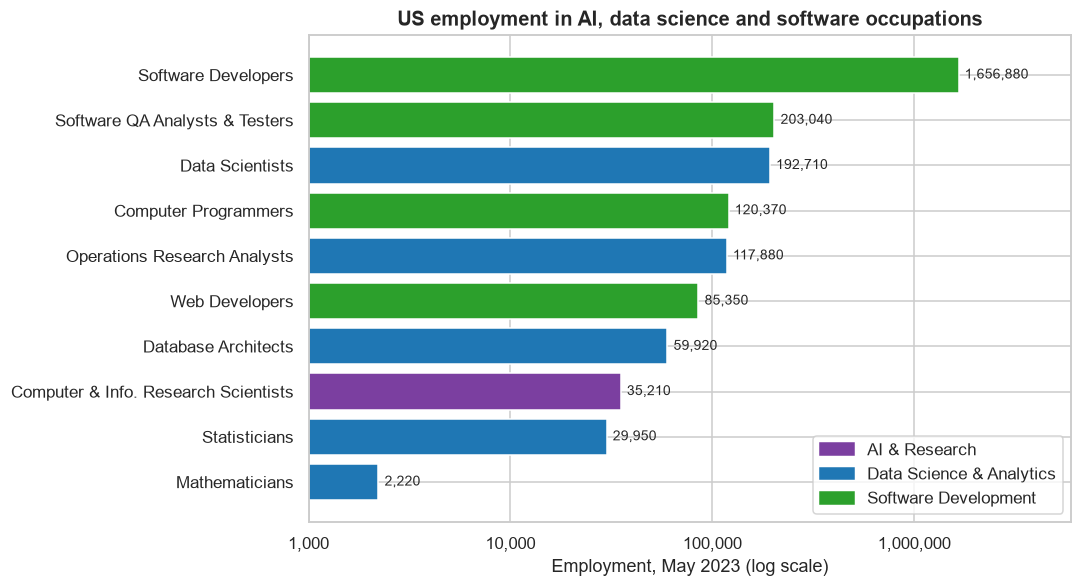

FAMILY
Software Development        82.5%
Data Science & Analytics    16.1%
AI & Research                1.4%


In [4]:
d = nat_occ.sort_values("TOT_EMP")
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(d.SHORT, d.TOT_EMP, color=d.FAMILY.map(FAMILY_COLORS))
ax.set_xscale("log")
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in d.TOT_EMP], padding=4, fontsize=9)
ax.set_xlim(1_000, 6_000_000)
ax.set_xlabel("Employment, May 2023 (log scale)")
ax.set_title("US employment in AI, data science and software occupations")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
ax.legend(handles, FAMILY_COLORS.keys(), loc="lower right", frameon=True)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout(); plt.show()

fam = nat_occ.groupby("FAMILY").TOT_EMP.sum().sort_values(ascending=False)
print((fam / fam.sum()).map("{:.1%}".format).to_string())

**What I learned about AI employment**
* **Software development dominates.** Software Developers alone number about **1.66 million**, two-thirds of the ~2.5 million jobs in the tracked group (software development as a family is ~83%). AI products need a far larger base of engineers to build and ship them than to invent the models.
* **Data Scientists (~193k) are the biggest "data" occupation and the third-largest occupation overall.** There were almost as many as Software QA testers and more than Programmers or Web Developers. This is the main applied AI and ML role in the SOC system, yet the whole Data Science & Analytics family is only ~16% of the group.
* **Core AI research is a small elite.** Computer & Information Research Scientists, the occupation that covers AI and ML researchers, number only **~35k**. That is about 1 for every 47 Software Developers.
* Mathematicians (~2k) are a tiny group, so "AI talent" in the labour market means applied data and software skills far more than pure maths.

### Visualisation 2: Box plot of the national wage distribution

**Objective: comparison of distributions.** How much do these occupations pay, and how wide is the spread inside each one compared with the average US job?

**Why a box plot?** Wage is a continuous variable. A single average hides inequality inside an occupation. OEWS publishes the 10th, 25th, 50th, 75th and 90th percentiles, which map directly onto a box plot: the box is the 25th to 75th percentile, the line is the median, and the whiskers are the 10th and 90th percentiles. The plot is built from these published percentiles with `matplotlib.bxp`, since individual wages aren't available. A dashed reference line shows the median for all US occupations.

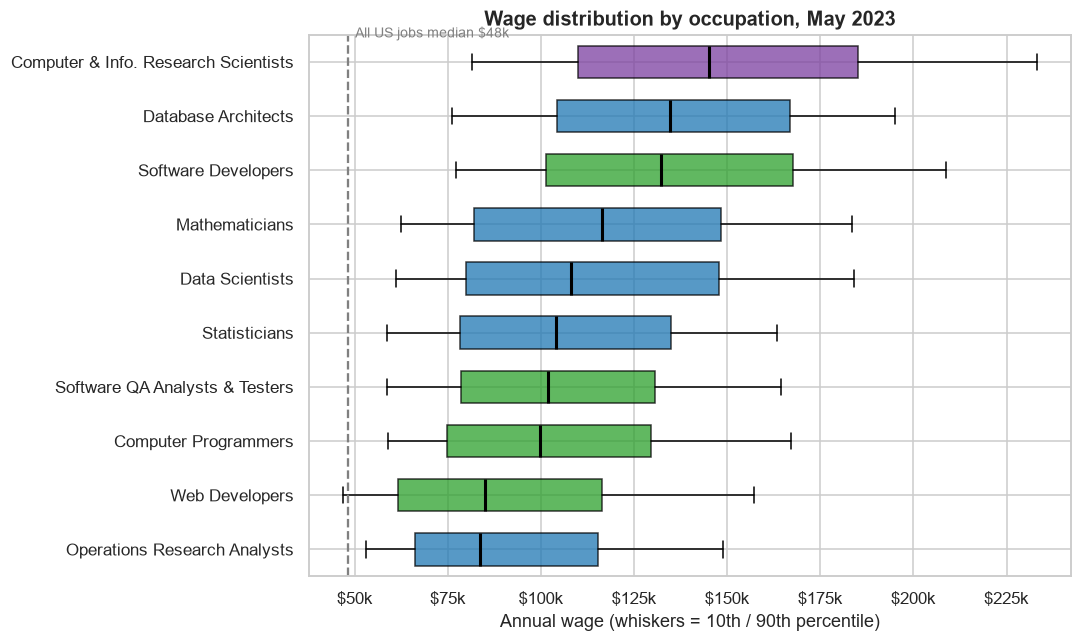

,SHORT,A_PCT10,A_MEDIAN,A_PCT90,premium
138,Computer & Info. Research Scientists,81450.0,145080.0,233110.0,3.02
145,Database Architects,76000.0,134700.0,194960.0,2.80
149,Software Developers,77020.0,132270.0,208620.0,2.75
159,Mathematicians,62260.0,116440.0,183500.0,2.42
165,Data Scientists,61070.0,108020.0,184090.0,2.25
163,Statisticians,58690.0,104110.0,163360.0,2.17
150,Software QA Analysts & Testers,58740.0,101800.0,164520.0,2.12
148,Computer Programmers,58950.0,99700.0,167230.0,2.07
151,Web Developers,46850.0,84960.0,157280.0,1.77
161,Operations Research Analysts,52930.0,83640.0,148920.0,1.74


In [5]:
d = nat_occ.sort_values("A_MEDIAN", ascending=True)
stats = [dict(label=r.SHORT, whislo=r.A_PCT10, q1=r.A_PCT25, med=r.A_MEDIAN,
              q3=r.A_PCT75, whishi=r.A_PCT90, fliers=[]) for r in d.itertuples()]
fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.bxp(stats, vert=False, patch_artist=True, showfliers=False, widths=0.6,
            medianprops=dict(color="black", linewidth=2))
for patch, fam in zip(bp["boxes"], d.FAMILY):
    patch.set_facecolor(FAMILY_COLORS[fam]); patch.set_alpha(0.75)
ax.axvline(all_median, ls="--", color="grey")
ax.text(all_median + 2000, 10.45, f"All US jobs median ${all_median/1000:.0f}k", color="grey", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.set_xlabel("Annual wage (whiskers = 10th / 90th percentile)")
ax.set_title("Wage distribution by occupation, May 2023")
plt.tight_layout(); plt.show()

nat_occ.assign(premium=lambda x: x.A_MEDIAN / all_median)[["SHORT", "A_PCT10", "A_MEDIAN", "A_PCT90", "premium"]] \
       .sort_values("A_MEDIAN", ascending=False).round(2)

**What I learned about AI employment**
* **AI research is the best-paid group.** Research Scientists have a median of about **$145k**, roughly **3x the median US job** ($48k). Their 90th percentile is about $233k, close to the BLS top-coding cap. Database Architects (~$135k) and Software Developers (~$132k) follow.
* **Almost every occupation's 10th percentile is above the national median.** The lowest-paid tenth of Data Scientists (~$61k) still earns more than the typical American worker. The one exception is Web Developers, whose 10th percentile (~$47k) sits just below the line.
* **Data Scientists have a lower median (~$108k) than Software Developers (~$132k) but a very wide spread.** The 10th–90th range runs from ~$61k to ~$184k. That mix of entry-level analysts and senior ML specialists fits a fast-growing occupation with many new entrants.
* Operations Research Analysts and Web Developers have the lowest medians (~$84–85k). Broadly, pay rises as the role moves closer to research, modelling and system architecture.

### Visualisation 3: Bubble scatter of employment, wage and concentration by state

**Objective: investigating a relationship.** Do states with *more* AI and data jobs also *pay more*, and which states specialise in this work?

**Why a bubble scatter plot?** Each state has two quantitative measures, employment and median wage. A scatter plot is the standard way to look for a relationship between two continuous variables. A third variable, the **location quotient** (LQ: the occupation's share of jobs in the state divided by its national share, so LQ > 1 means more concentrated than the US average), is shown as bubble size. Employment uses a log axis because California is an outlier. The largest states are labelled.

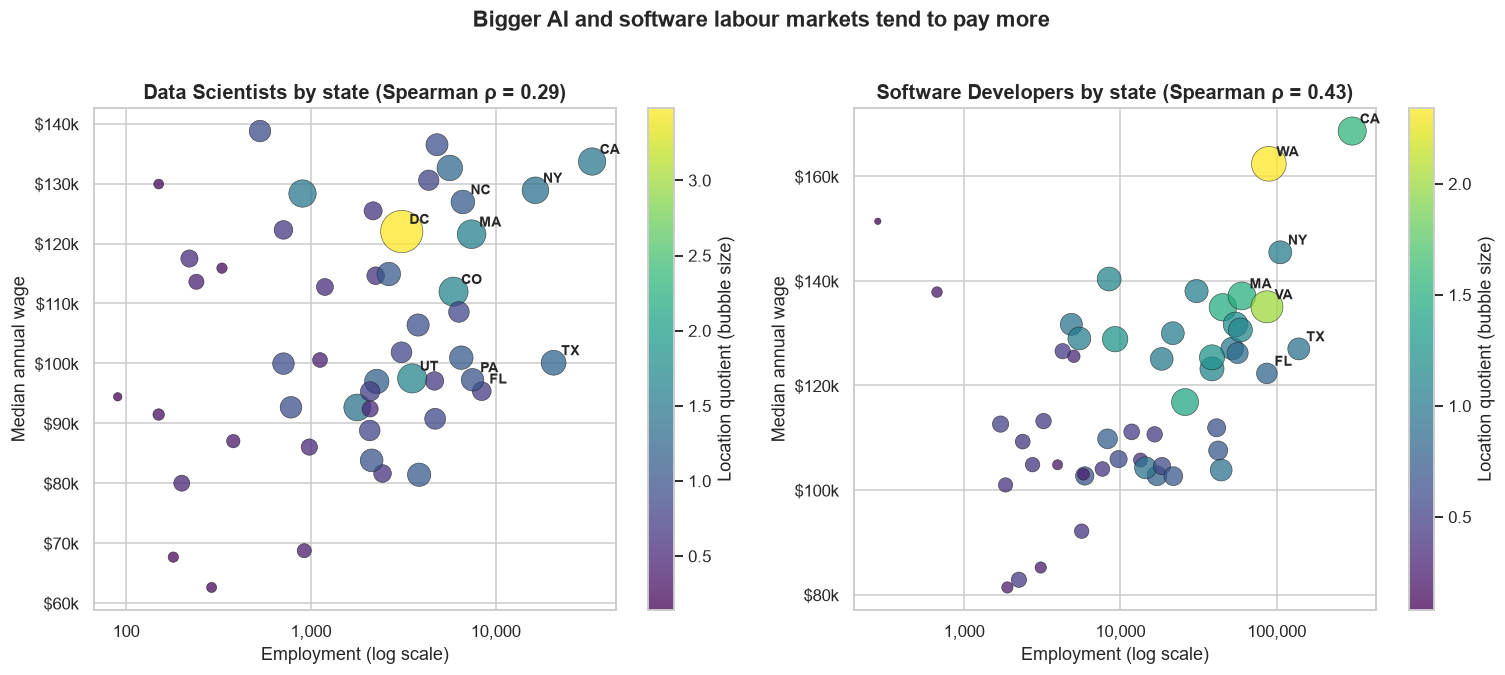

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
for ax, code_, title in zip(axes, ["15-2051", "15-1252"], ["Data Scientists", "Software Developers"]):
    s = states[(states.OCC_CODE == code_)].dropna(subset=["TOT_EMP", "A_MEDIAN", "LOC_QUOTIENT"])
    sc = ax.scatter(s.TOT_EMP, s.A_MEDIAN, s=s.LOC_QUOTIENT * 220, c=s.LOC_QUOTIENT,
                    cmap="viridis", alpha=0.75, edgecolor="k", linewidth=0.4)
    ax.set_xscale("log")
    top = pd.concat([s.nlargest(7, "TOT_EMP"), s.nlargest(3, "LOC_QUOTIENT")]).drop_duplicates("AREA_TITLE")
    for r in top.itertuples():
        ax.annotate(r.PRIM_STATE, (r.TOT_EMP, r.A_MEDIAN), fontsize=9, fontweight="bold",
                    xytext=(5, 5), textcoords="offset points")
    rho = s[["TOT_EMP", "A_MEDIAN"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{title} by state (Spearman ρ = {rho:.2f})")
    ax.set_xlabel("Employment (log scale)"); ax.set_ylabel("Median annual wage")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    fig.colorbar(sc, ax=ax, label="Location quotient (bubble size)")
plt.suptitle("Bigger AI and software labour markets tend to pay more", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**What I learned about AI employment**
* **There is a positive relationship: bigger tech labour markets pay more.** It is moderate for Software Developers (ρ ≈ 0.43) and weaker for Data Scientists (ρ ≈ 0.29). This is consistent with agglomeration: talent, employers and pay cluster together. The weaker link for data science suggests its pay depends more on *which* industries are present (e.g. finance) than on market size alone.
* **California leads on both size and pay.** It has ~33k Data Scientists (median ~$134k) and ~304k Software Developers (median ~$169k).
* **Concentration and size are different things.** DC is a small market but has the highest Data Scientist concentration (LQ > 3). Washington (WA) and Virginia (VA) have the highest location quotients for software. Big tech HQs in Seattle and the federal and defence tech economy around DC make these jobs a far larger share of local employment than their population alone would suggest.
* Texas and Florida have large *counts* but average or below-average concentration and noticeably lower wages. They are big markets but not specialised AI hubs.

### Visualisation 4: Donut chart of the industries that employ Data Scientists

**Objective: composition (part-to-whole).** Which industries hire the people doing applied AI and data science?

**Why a donut (pie) chart?** The question is about *shares of one whole*: all Data Scientists split across mutually exclusive NAICS sectors. A pie or donut chart is built for part-to-whole questions when there are only a few categories, so the top 6 sectors are kept and the rest are grouped into "Other". The hole in the middle holds the total, and a second donut shows Software Developers for comparison.

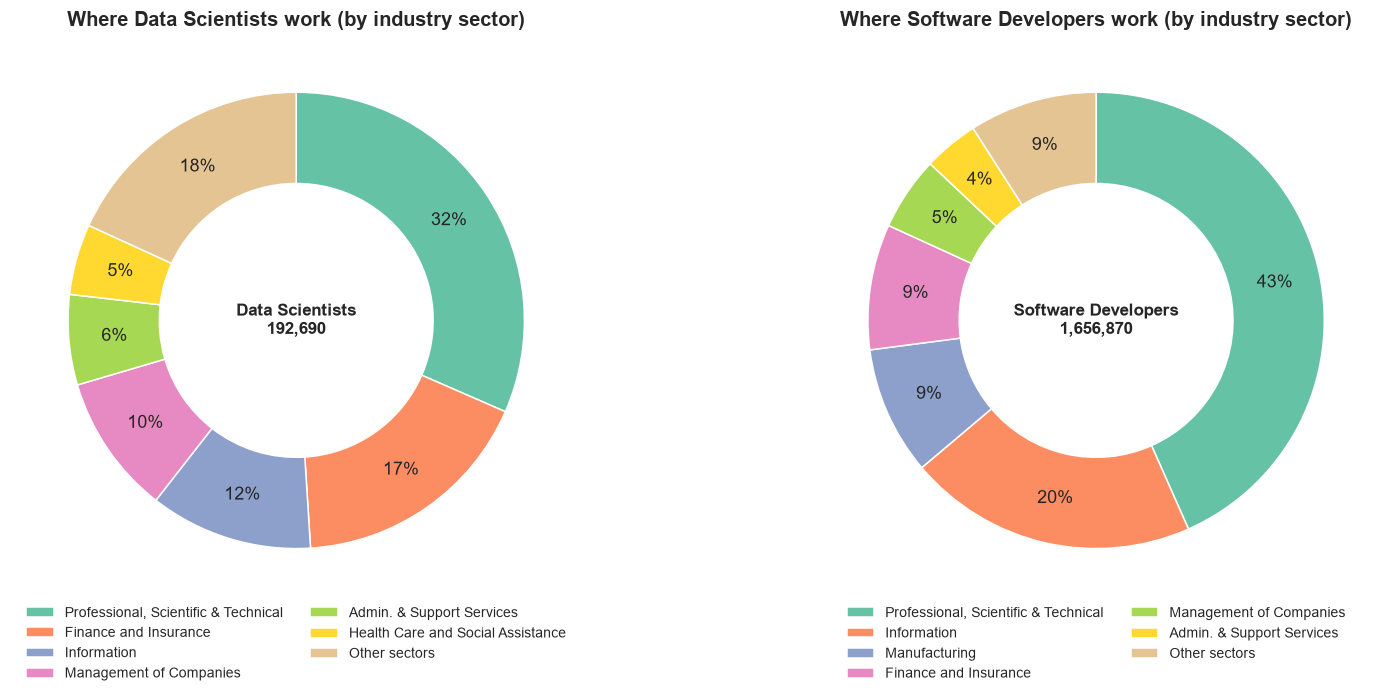

In [7]:
def sector_share(code_, top_n=6):
    s = sectors[sectors.OCC_CODE == code_].dropna(subset=["TOT_EMP"]).copy()
    s["label"] = s.NAICS_TITLE.str.replace(r"\s*\(OEWS Designation\)", "", regex=True) \
                  .str.replace("Federal, State, and Local Government, excluding State and Local Government Schools and Hospitals and the U.S. Postal Service", "Government") \
                  .str.replace("Administrative and Support and Waste Management and Remediation Services", "Admin. & Support Services") \
                  .str.replace("Professional, Scientific, and Technical Services", "Professional, Scientific & Technical") \
                  .str.replace("Management of Companies and Enterprises", "Management of Companies")
    s = s.sort_values("TOT_EMP", ascending=False)
    out = s.head(top_n).set_index("label").TOT_EMP
    out["Other sectors"] = s.iloc[top_n:].TOT_EMP.sum()
    return out

pal = sns.color_palette("Set2", 7)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, code_, title in zip(axes, ["15-2051", "15-1252"], ["Data Scientists", "Software Developers"]):
    sh = sector_share(code_)
    wedges, *_ = ax.pie(sh, labels=None, autopct="%1.0f%%", pctdistance=0.8, startangle=90,
                        counterclock=False, colors=pal, wedgeprops=dict(width=0.4, edgecolor="white"))
    ax.text(0, 0, f"{title}\n{sh.sum():,.0f}", ha="center", va="center", fontsize=11, fontweight="bold")
    ax.legend(wedges, sh.index, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, fontsize=9, frameon=False)
    ax.set_title(f"Where {title} work (by industry sector)")
plt.tight_layout(); plt.show()

**What I learned about AI employment**
* **Professional, Scientific & Technical Services is the largest employer of Data Scientists (~32%).** This sector covers consulting firms, computer-systems design firms and R&D labs. A lot of AI work is delivered *as a service* to other companies.
* **Finance & Insurance is the second-largest home for Data Scientists (~17%),** almost double its share of Software Developers (~9%). Risk models, fraud detection and algorithmic trading made finance an early, heavy adopter of data science and ML.
* The Information sector (software publishers, internet platforms) and corporate HQs ("Management of Companies") come next. Health care already employs ~10k Data Scientists (~5%), so AI demand is spreading beyond tech.
* Software Developers are more concentrated: ~63% work in Professional & Technical Services or Information, against ~44% of Data Scientists. Data science is more *spread across industries*, which suggests AI and data skills are becoming a general business function rather than a tech-sector specialty.

### Visualisation 5: Heatmap of location quotients by state and occupation

**Objective: investigation and pattern-finding.** Which states specialise in which kinds of AI, data and software work?

**Why a heatmap?** The data is a matrix of two categorical dimensions (state × occupation) with one quantitative value (location quotient) in each cell. A heatmap shows the whole matrix at once, so rows (states with broad tech specialisation) and columns (occupations with geographic clustering) stand out. A **diverging colour map centred on 1.0** is used because LQ has a natural midpoint: red means more concentrated than the US average, blue means less. The 15 states with the most jobs in the tracked occupations are shown.

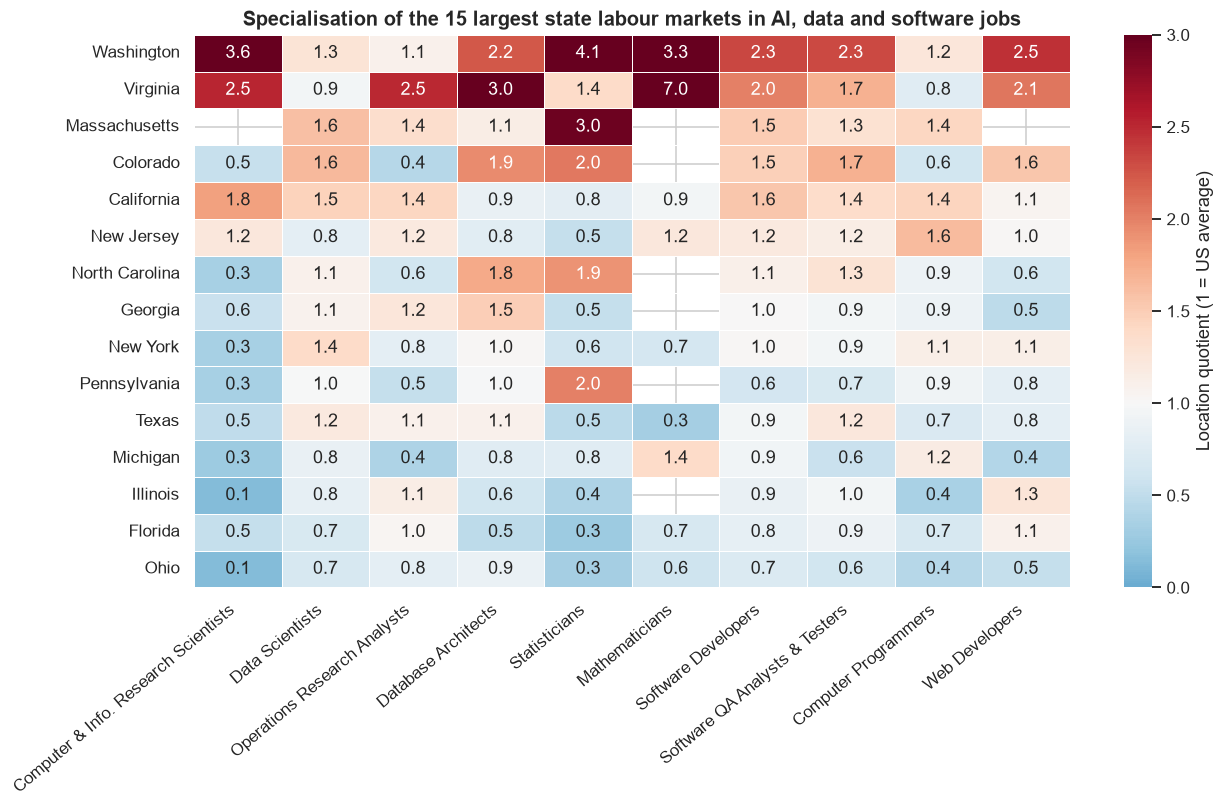

In [8]:
top_states = states.groupby("AREA_TITLE").TOT_EMP.sum().nlargest(15).index
lq = states[states.AREA_TITLE.isin(top_states)].pivot_table(index="AREA_TITLE", columns="SHORT", values="LOC_QUOTIENT")
order_cols = nat_occ.sort_values(["FAMILY", "TOT_EMP"], ascending=[True, False]).SHORT
lq = lq[[c for c in order_cols if c in lq.columns]]
lq = lq.loc[lq.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 7.5))
sns.heatmap(lq, cmap="RdBu_r", center=1, vmin=0, vmax=3, annot=True, fmt=".1f",
            linewidths=0.5, cbar_kws={"label": "Location quotient (1 = US average)"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Specialisation of the 15 largest state labour markets in AI, data and software jobs")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

**What I learned about AI employment**
* **Washington and Virginia are the most specialised states, red in almost every column.** Washington's LQ for Computer & Information Research Scientists is ~3.6 and Virginia's ~2.5. That reflects big-tech AI labs around Seattle and the federal, defence and intelligence research economy around DC. Virginia's LQ of 7.0 for Mathematicians points the same way. Maryland, just outside the top 15 by size, has an even higher research-scientist LQ (~3.7).
* **Massachusetts** (the Boston university and biotech cluster, with a Statisticians LQ of 3.0), **Colorado** and **California** are above average across most columns. They are broad AI ecosystems rather than one-occupation hubs. Blank cells are estimates BLS suppressed for confidentiality.
* **AI research is the most geographically clustered occupation.** Its column ranges from 0.1 (Ohio, Illinois) to 3.6 (Washington), the widest range of any occupation, while Software Developers vary only from 0.6 to 2.3. Advanced AI work concentrates in a few hubs, while general software jobs are everywhere.
* Large states such as Florida, Ohio and Pennsylvania are mostly blue. They have many tech workers in absolute terms but are not specialised in AI.

### Visualisation 6: Violin plot of median wages across metropolitan areas

**Objective: distribution and comparison across places.** Visualisation 2 showed pay variation *within* an occupation nationally. This one asks how much pay varies *between cities* for the same job, and whether that geographic gap is bigger for AI and data roles.

**Why a violin plot?** There are several hundred metro-area medians per occupation, a continuous variable with a real distribution shape (skew, long tails). A violin combines a box plot with a kernel density estimate, so it shows both summary statistics *and* the shape, such as a long right tail of high-paying tech hubs. Showing the violins side by side makes the occupations easy to compare. Only occupations with enough metro-level estimates are included.

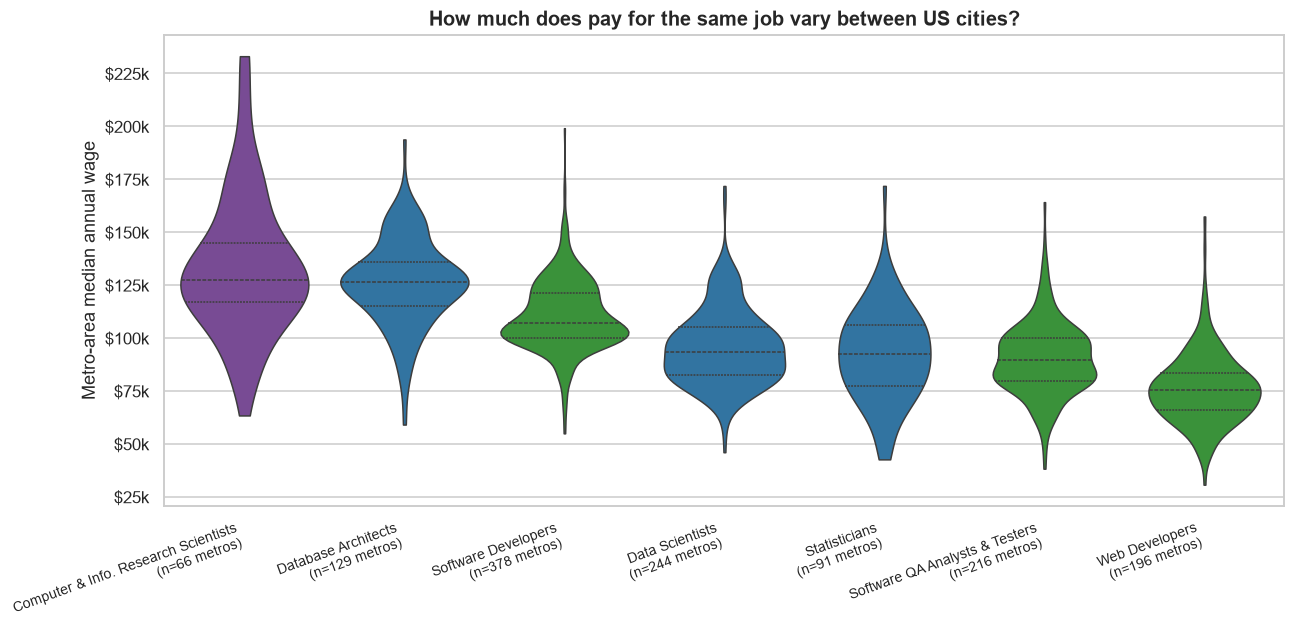

Top-paying metros for Data Scientists (median wage):
                                  AREA_TITLE  TOT_EMP  A_MEDIAN
          San Jose-Sunnyvale-Santa Clara, CA   5040.0  171800.0
           San Francisco-Oakland-Hayward, CA   8870.0  163430.0
             Bridgeport-Stamford-Norwalk, CT    290.0  137420.0
                 Seattle-Tacoma-Bellevue, WA   4810.0  135610.0
Washington-Arlington-Alexandria, DC-VA-MD-WV   6840.0  135080.0


In [9]:
v_codes = ["15-1221", "15-2051", "15-1243", "15-2041", "15-1252", "15-1253", "15-1254"]
v = metros[metros.OCC_CODE.isin(v_codes)].dropna(subset=["A_MEDIAN"])
order = v.groupby("SHORT").A_MEDIAN.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 6))
sns.violinplot(data=v, x="SHORT", y="A_MEDIAN", order=order, hue="FAMILY", palette=FAMILY_COLORS,
               dodge=False, inner="quartile", cut=0, linewidth=1, ax=ax, legend=False)
counts = v.groupby("SHORT").size()
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{o}\n(n={counts[o]} metros)" for o in order], rotation=20, ha="right", fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f"${v_/1000:.0f}k"))
ax.set_xlabel(""); ax.set_ylabel("Metro-area median annual wage")
ax.set_title("How much does pay for the same job vary between US cities?")
plt.tight_layout(); plt.show()

print("Top-paying metros for Data Scientists (median wage):")
print(metros[metros.OCC_CODE == "15-2051"].nlargest(5, "A_MEDIAN")[["AREA_TITLE", "TOT_EMP", "A_MEDIAN"]].to_string(index=False))

**What I learned about AI employment**
* **Software Developers appear in far more metros than AI researchers.** BLS publishes software-developer wages for 378 metros but research-scientist wages for only 66. AI research jobs simply don't exist in most local labour markets.
* **Every distribution has a long upper tail.** In most cities pay clusters together (the typical metro pays Data Scientists ~$93k), but a few hubs pay far above the rest. For Data Scientists, San Jose (~$172k) and San Francisco (~$163k) are 60–80% above that typical-metro level.
* **Location matters about as much as occupation.** A Data Scientist in a top metro can earn more than a Software Developer in a typical metro, so where you work changes AI pay as much as your job title does.

### Visualisation 7: Lollipop chart of the top 15 metros for Data Scientists

**Objective: ranking.** Which cities are the largest job markets for Data Scientists?

**Why a lollipop chart?** This is a ranking of one quantitative value across categories. A lollipop is a cleaner version of a bar chart that uses less ink, which helps when the list is long. Colouring each dot by median wage adds a second variable without cluttering the chart.

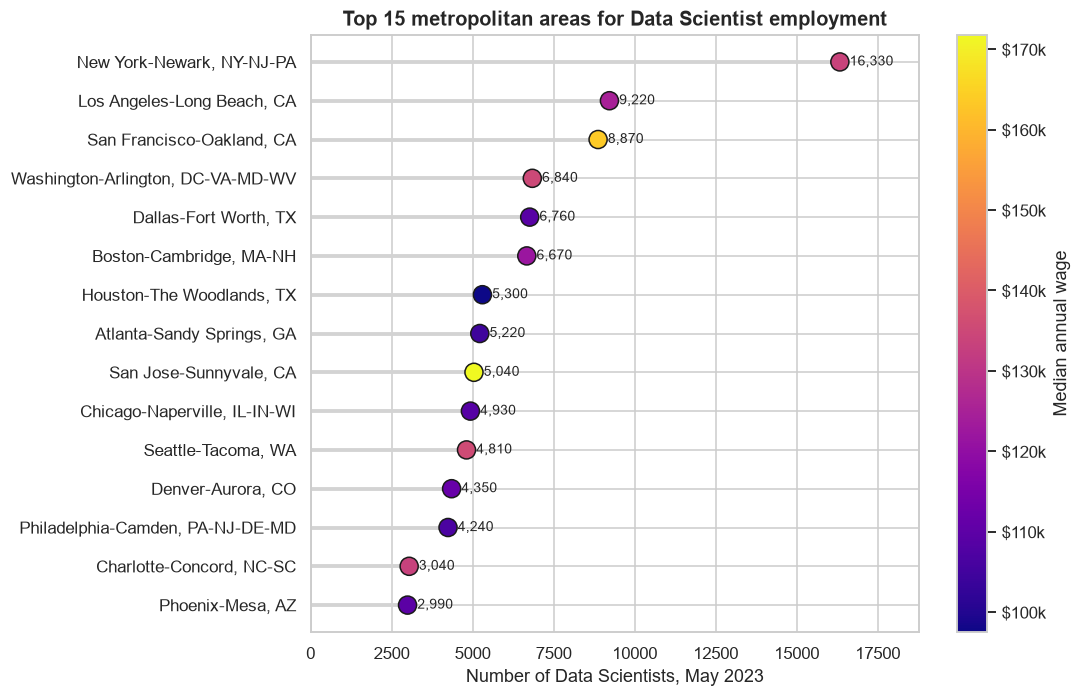

In [10]:
m = metros[metros.OCC_CODE == "15-2051"].nlargest(15, "TOT_EMP").sort_values("TOT_EMP")
m["label"] = m.AREA_TITLE.str.split(",").str[0].str.split("-").str[:2].str.join("-") + ", " + m.AREA_TITLE.str.split(", ").str[-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.hlines(m.label, 0, m.TOT_EMP, color="lightgrey", linewidth=2.5)
sc = ax.scatter(m.TOT_EMP, m.label, c=m.A_MEDIAN, cmap="plasma", s=140, zorder=3, edgecolor="k")
for r in m.itertuples():
    ax.text(r.TOT_EMP + 300, r.label, f"{r.TOT_EMP:,.0f}", va="center", fontsize=9)
cb = fig.colorbar(sc, ax=ax); cb.set_label("Median annual wage")
cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f"${v_/1000:.0f}k"))
ax.set_xlabel("Number of Data Scientists, May 2023"); ax.set_xlim(0, m.TOT_EMP.max() * 1.15)
ax.set_title("Top 15 metropolitan areas for Data Scientist employment")
plt.tight_layout(); plt.show()

**What I learned about AI employment**
* **New York is the largest Data Science job market (~16k), almost twice the size of any Californian metro.** This matches Visualisation 4: finance is a major employer of data scientists.
* **Size and pay are not the same ranking.** San Francisco and San Jose have the highest dot colours (medians above $160k) despite smaller headcounts than New York or Los Angeles. Dallas, Houston and Atlanta are large markets with noticeably lower pay.
* Data science jobs are spread across many large metros (Washington DC, Boston, Chicago, Seattle, Texas cities and others), not just Silicon Valley.

## 3. Challenge: AI employment trends over time

The May 2023 file is a snapshot. To see trends I use the **national** OEWS files for earlier years from the same BLS page (<https://www.bls.gov/oes/tables.htm>). These are much smaller than the "all data" files but contain the same national occupation rows.

**How to get the files.** BLS blocks scripted downloads, so download them manually in a browser. On the tables page, click the **"National"** XLSX link for each year, or use these direct links:
`https://www.bls.gov/oes/special-requests/oesm22nat.zip`, `oesm21nat.zip`, … `oesm15nat.zip`.
Save the `.zip` files (or the extracted `national_M20XX_dl.xlsx` files) into a folder called **`historical_data/`** next to this notebook. The cell below finds them automatically. Data for 2023 comes from the main all-data file already loaded.

**Handling SOC classification changes (important).** BLS moved from the 2010 SOC to the 2018 SOC during 2019–2021, so some occupation codes changed:

| Series | 2015–2018 (2010 SOC) | 2019–2020 (hybrid) | 2021+ (2018 SOC) |
|---|---|---|---|
| Software Developers | 15-1132 + 15-1133 | 15-1256 *(incl. QA testers)* | 15-1252 + 15-1253 *(re-combined incl. QA for consistency)* |
| Computer & Info. Research Scientists | 15-1111 | 15-1221 | 15-1221 |
| Data Scientists | n/a (inside 15-2099 "Math. Science, All Other") | 15-2098 *(Data Scientists + Math. Science All Other)* | 15-2051 |
| Information Security Analysts | 15-1122 | 15-1212 | 15-1212 |
| All Computer & Mathematical (15-0000) | 15-0000 | 15-0000 | 15-0000 |

The mapping function picks the right codes for each year, so the series are as comparable as the classification allows. Breaks in the series are flagged in the charts.

In [11]:
HIST_DIR = "historical_data"

def read_national(path):
    # Read a BLS national OEWS file (.zip or .xlsx) and normalise column names across years
    if path.lower().endswith(".zip"):
        with zipfile.ZipFile(path) as z:
            name = [n for n in z.namelist() if n.lower().endswith((".xlsx", ".xls")) and "national" in n.lower()
                    and "field_descriptions" not in n.lower()][0]
            with z.open(name) as f:
                d = pd.read_excel(f)
    else:
        d = pd.read_excel(path)
    d.columns = [c.upper().strip() for c in d.columns]
    d = d.rename(columns={"OCC_GROUP": "O_GROUP"})
    for c in ["TOT_EMP", "A_MEAN", "A_MEDIAN"]:
        d[c] = to_num(d[c].astype(str).str.replace(",", ""))
    return d[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]]

hist = {}
for p in sorted(glob.glob(os.path.join(HIST_DIR, "*"))):
    m_ = re.search(r"(?:oesm(\d{2})nat|M(20\d{2}))", os.path.basename(p), re.I)
    if not m_:
        continue
    yr = 2000 + int(m_.group(1)) if m_.group(1) else int(m_.group(2))
    if yr not in hist and yr < 2023:
        hist[yr] = read_national(p)
hist[2023] = national[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]].copy()
print("Years available:", sorted(hist))
if len(hist) == 1:
    print("\n⚠ No historical files found in ./historical_data/. Download them as described above and re-run this section.")

Years available: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [12]:
# For each series, list the code sets in order of preference. The first set fully present in a year is used.
SERIES = {
    "Software Developers (incl. QA)":       [["15-1252", "15-1253"], ["15-1256"], ["15-1132", "15-1133"]],
    "Computer & Info. Research Scientists": [["15-1221"], ["15-1111"]],
    "Data Scientists":                      [["15-2051"], ["15-2098"]],
    "Information Security Analysts":        [["15-1212"], ["15-1122"]],
    "All Computer & Mathematical":          [["15-0000"]],
    "All occupations":                      [["00-0000"]],
}

rows = []
for yr, d in sorted(hist.items()):
    d = d.drop_duplicates("OCC_CODE").set_index("OCC_CODE")
    for name, options in SERIES.items():
        for codes in options:
            if all(c in d.index for c in codes):
                sub = d.loc[codes]
                emp = sub.TOT_EMP.sum()
                wage = np.average(sub.A_MEAN, weights=sub.TOT_EMP)  # employment-weighted mean wage
                rows.append(dict(year=yr, series=name, codes="+".join(codes), emp=emp, mean_wage=wage))
                break
trend = pd.DataFrame(rows)
trend.pivot(index="year", columns="series", values="emp").style.format("{:,.0f}", na_rep="-")

series,All Computer & Mathematical,All occupations,Computer & Info. Research Scientists,Data Scientists,Information Security Analysts,Software Developers (incl. QA)
year,,,,,,
2015,"4,005,250","137,896,660","25,510",-,"88,880","1,138,480"
2016,"4,165,140","140,400,040","26,580",-,"96,870","1,203,820"
2017,"4,261,460","142,549,250","27,920",-,"105,250","1,243,820"
2018,"4,384,300","144,733,270","30,070",-,"108,060","1,308,490"
2019,"4,552,880","146,875,480","30,780","30,810","125,570","1,406,870"
2020,"4,587,700","139,099,570","30,220","59,680","138,000","1,476,800"
2021,"4,654,750","140,886,310","30,840","105,980","157,220","1,554,300"
2022,"5,003,910","147,886,000","33,780","159,630","163,690","1,731,210"
2023,"5,177,400","151,853,870","35,210","192,710","175,350","1,859,920"


### Visualisation 8: Line chart of employment trends (absolute and indexed)

**Objective: tracking change over time.** Has employment in AI, data and software occupations grown faster than the overall US labour market?

**Why a line chart?** Year is an ordered, continuous time variable, and lines show trend, slope and turning points better than any other chart type. Two panels are used:
* **Left (log scale):** absolute employment, so series of very different sizes fit on one axis and equal slopes mean equal *percentage* growth.
* **Right (indexed):** each series rebased to 100 in its first comparable year. This answers the real question, *which grew fastest*, directly. Dashed segments mark years where a SOC reclassification breaks comparability.

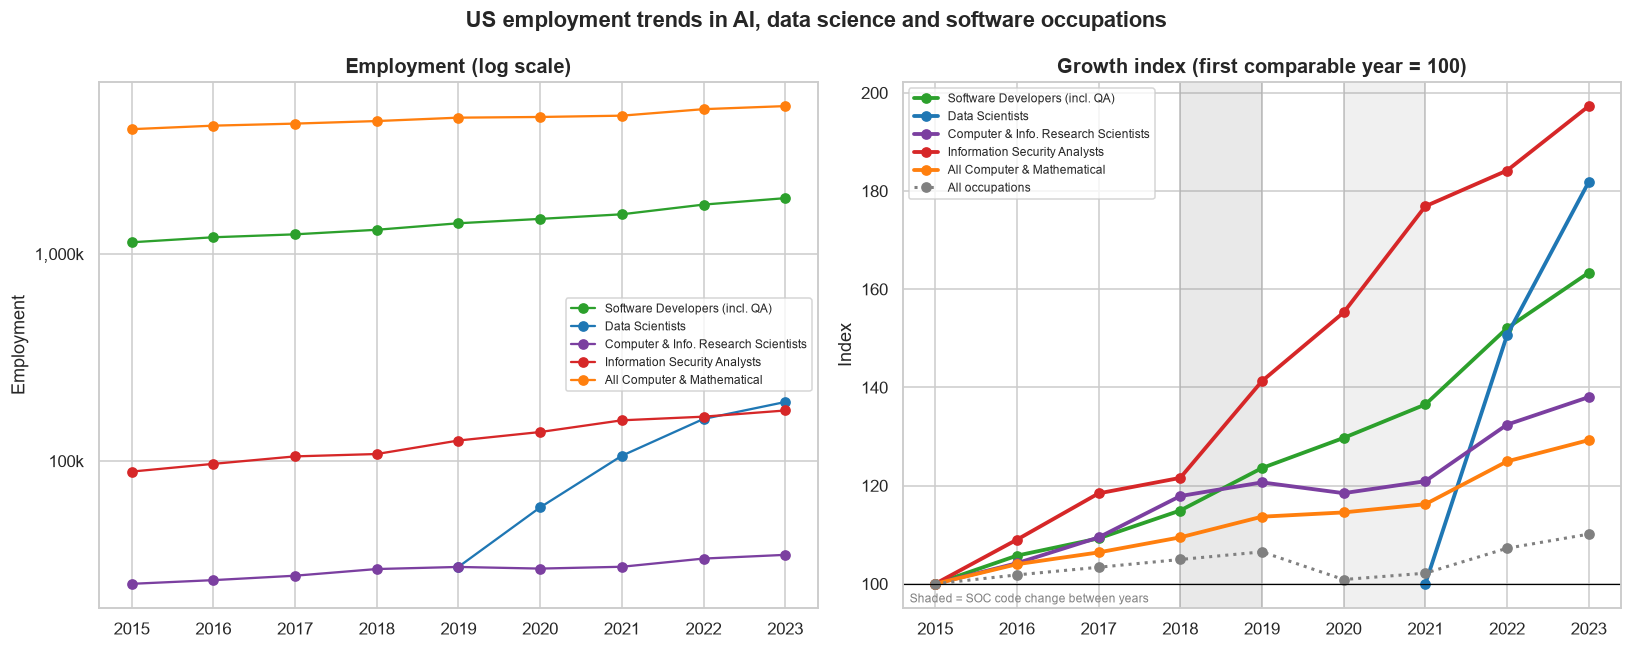

year,2015,2023,total growth,CAGR
series,,,,
All Computer & Mathematical,"4,005,250","5,177,400",+29%,+3.3%
All occupations,"137,896,660","151,853,870",+10%,+1.2%
Computer & Info. Research Scientists,"25,510","35,210",+38%,+4.1%
Data Scientists,nan,"192,710",+nan%,+nan%
Information Security Analysts,"88,880","175,350",+97%,+8.9%
Software Developers (incl. QA),"1,138,480","1,859,920",+63%,+6.3%


Note: Data Scientists growth across the 2020→2021 SOC change is not like-for-like (see table above).


In [13]:
if trend.year.nunique() < 2:
    print("Need at least 2 years of data. Add the historical files to ./historical_data/ and re-run.")
else:
    plot_series = ["Software Developers (incl. QA)", "Data Scientists", "Computer & Info. Research Scientists",
                   "Information Security Analysts", "All Computer & Mathematical", "All occupations"]
    colors = dict(zip(plot_series, ["#2ca02c", "#1f77b4", "#7b3fa0", "#d62728", "#ff7f0e", "grey"]))
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for s_ in plot_series[:-1]:
        t = trend[trend.series == s_].sort_values("year")
        axes[0].plot(t.year, t.emp, marker="o", color=colors[s_], label=s_)
    axes[0].set_yscale("log")
    axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f"{v_/1000:,.0f}k"))
    axes[0].set_title("Employment (log scale)"); axes[0].set_ylabel("Employment"); axes[0].legend(fontsize=8)

    for s_ in plot_series:
        t = trend[trend.series == s_].sort_values("year").copy()
        # Rebase each series to the first year of its current code set, which avoids indexing across a SOC break
        last_codes = t.codes.iloc[-1]
        base_t = t[t.codes == last_codes] if s_ in ("Data Scientists",) else t
        base = base_t.emp.iloc[0]
        t["idx"] = t.emp / base * 100
        consistent = t[t.codes == last_codes] if s_ == "Data Scientists" else t
        axes[1].plot(consistent.year, consistent.idx, marker="o", color=colors[s_], label=s_,
                     lw=2.5 if s_ != "All occupations" else 2, ls="-" if s_ != "All occupations" else ":")
        # Mark SOC code changes with a dashed connector
        for (y0, c0), (y1, c1) in zip(t[["year", "codes"]].values[:-1], t[["year", "codes"]].values[1:]):
            if c0 != c1:
                axes[1].axvspan(y0, y1, color="grey", alpha=0.06)
    axes[1].axhline(100, color="black", lw=0.8)
    axes[1].set_title("Growth index (first comparable year = 100)")
    axes[1].set_ylabel("Index"); axes[1].legend(fontsize=8)
    axes[1].text(0.01, 0.01, "Shaded = SOC code change between years", transform=axes[1].transAxes, fontsize=8, color="grey")
    for ax in axes:
        ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
    plt.suptitle("US employment trends in AI, data science and software occupations", fontweight="bold")
    plt.tight_layout(); plt.show()

    first, last = trend.year.min(), trend.year.max()
    g = trend[trend.year.isin([first, last])].pivot(index="series", columns="year", values="emp")
    g["total growth"] = (g[last] / g[first] - 1)
    g["CAGR"] = (g[last] / g[first]) ** (1 / (last - first)) - 1
    display(g.style.format({first: "{:,.0f}", last: "{:,.0f}", "total growth": "{:+.0%}", "CAGR": "{:+.1%}"}))
    print("Note: Data Scientists growth across the 2020→2021 SOC change is not like-for-like (see table above).")

### Visualisation 9: Grouped bar chart of mean wage over time

**Objective: comparison over time.** Has pay for AI and data roles kept pace with pay for the workforce as a whole?

**Why a grouped bar chart?** With only a few discrete years per series, grouped bars make year-by-year comparisons *within* each occupation easy, and the general wage level comparison *between* occupations is visible at the same time. Nominal (not inflation-adjusted) mean wages are shown, as published by BLS.

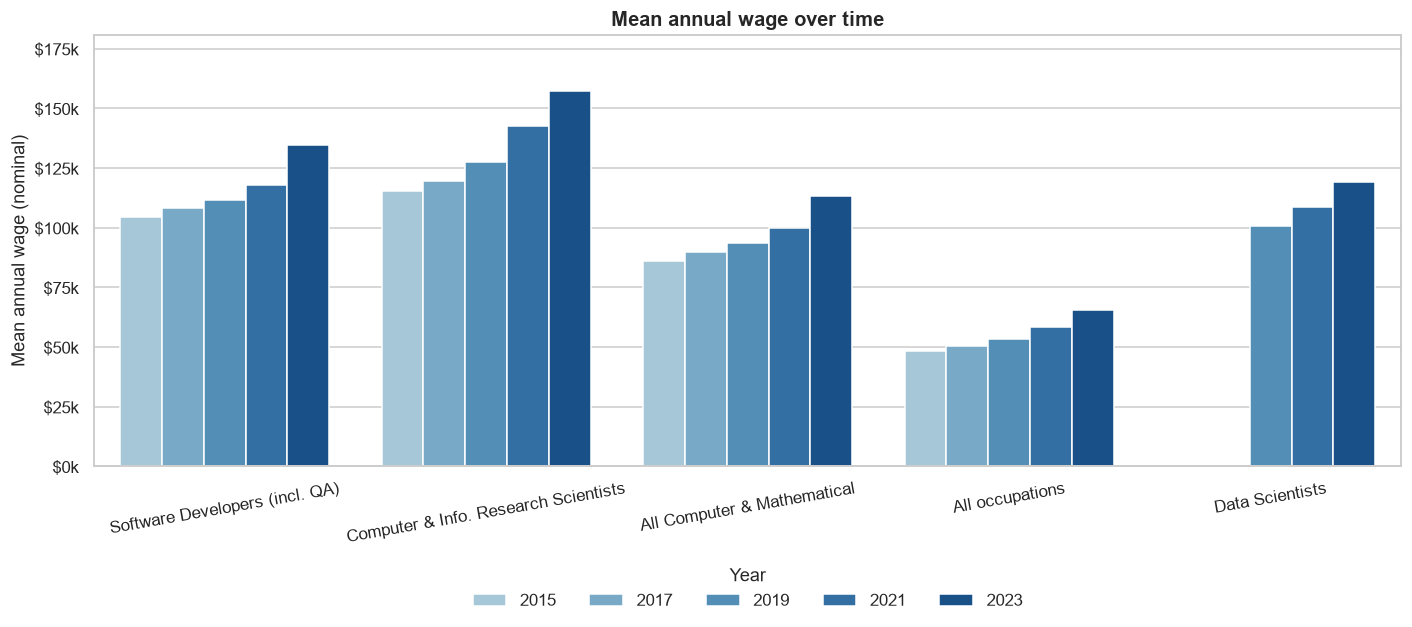

In [14]:
if trend.year.nunique() < 2:
    print("Need at least 2 years of data. Add the historical files to ./historical_data/ and re-run.")
else:
    w = trend[trend.series.isin(["Computer & Info. Research Scientists", "Software Developers (incl. QA)",
                                 "Data Scientists", "All Computer & Mathematical", "All occupations"])]
    w = w[w.year.isin(sorted(w.year.unique())[::2] + [w.year.max()])]  # every other year keeps the chart readable
    fig, ax = plt.subplots(figsize=(13, 6))
    n_years = w.year.nunique()
    sns.barplot(data=w, x="series", y="mean_wage", hue="year",
                palette=sns.color_palette("Blues", n_years + 2)[2:], ax=ax)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f"${v_/1000:.0f}k"))
    ax.set_xlabel(""); ax.set_ylabel("Mean annual wage (nominal)")
    ax.set_title("Mean annual wage over time")
    ax.set_ylim(0, w.mean_wage.max() * 1.15)
    plt.xticks(rotation=10)
    ax.legend(title="Year", ncol=n_years, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
    plt.tight_layout(); plt.show()

**What I learned about AI employment trends**

*Figures from the national OEWS files for May 2015 – May 2023.*

**From the line charts (Visualisation 8):**
* **Tech and AI jobs grew about three times faster than the economy.** Total US employment rose ~10% from 2015 to 2023 (137.9M to 151.9M). All Computer & Mathematical occupations rose ~29% (4.0M to 5.2M).
* **Data Scientists are the fastest-growing occupation in the dataset.** Since getting their own SOC code in 2021 they rose from ~106k to ~193k, **+82% in just two years**. That is far faster than Software Developers (+20%) or Research Scientists (+14%) over the same period. This is the clearest sign of the ML and AI hiring boom before ChatGPT. *(The 2019–2020 values come from the transitional code 15-2098 and are not comparable, which is why the index chart starts this series in 2021.)*
* **AI research is growing, but slowly and from a small base.** Computer & Information Research Scientists rose from ~25.5k to ~35.2k (+38% since 2015). Growth was flat in 2018–2021 and then picked up in 2022–2023 (+14%), which matches the industry's renewed investment in AI labs.
* **Information Security Analysts nearly doubled (+97%),** the steepest long-run growth of any series. As AI and data systems spread, the need to secure them is growing too.
* **Software Developers grew ~63% since 2015.** Part of the 2018→2019 step comes from the SOC change adding QA testers into the series (shaded band). The like-for-like 2021–2023 growth was still a strong +20%.
* **Resilient through COVID-19.** In 2020 total US employment fell ~5% (146.9M to 139.1M), but Computer & Mathematical jobs still grew, and Software Developer jobs rose ~5%. Remote-capable tech work was largely protected from the pandemic shock.

**From the grouped bar chart (Visualisation 9):**
* **AI research pay has pulled away from everyone else.** The mean wage for Research Scientists rose from ~$116k (2015) to ~$157k (2023), +36%. Most of that came in 2020–2022 (+19%), when competition for AI talent intensified.
* **Pay in tech grew roughly in line with the overall workforce in percentage terms** (Computer & Mathematical +31% against +35% for all occupations). The *dollar* gap widened, though: from ~$38k to ~$48k above the average job. Part of the all-occupations rise is a composition effect, since many low-wage jobs were lost in 2020.
* **Data Scientist pay grew slower than headcount.** The mean wage rose only ~10% between 2021 and 2023 while employment rose 82%. Rapid growth was met by a large inflow of new, often junior, workers, so demand was met mostly by *more people* rather than *higher pay*.

## 4. Summary of findings

1. **Scale:** The ten AI, data and software occupations tracked here account for roughly 2.5 million US jobs (~1.65% of employment). Software Developers dominate, Data Scientists (~193k) are the main applied AI/ML occupation, and core AI research (~35k Research Scientists) is a small, elite group.
2. **Pay:** Every occupation studied pays well above the US median ($48k). AI research has the highest median (~$145k, about 3x the national median). Data Science has one of the widest within-occupation spreads, which suggests a mix of junior and very senior roles.
3. **Industry:** Data science is spread across the economy. Professional & technical services lead, but finance & insurance employs about a sixth of all Data Scientists, and health care already employs ~10k.
4. **Geography:** AI work is strongly clustered. Research Scientists concentrate in Washington, Maryland, Virginia, California and Massachusetts, while general software jobs are much more evenly distributed. Larger tech labour markets pay more, and location can matter as much as job title.
5. **Trends (challenge):** From 2015 to 2023, computer and mathematical jobs grew ~29% against ~10% for all jobs. Data Scientists were the breakout occupation (+82% in 2021–2023 alone), AI research employment accelerated after 2021 with the fastest wage growth, and tech employment held up through the 2020 COVID downturn.

**Limitations**
* OEWS counts *occupations*, not *skills*. Many people doing AI work are classified as Software Developers or "Computer Occupations, All Other", so these figures are proxies.
* The 2018 SOC reclassification limits like-for-like comparisons before 2021, especially for Data Scientists.
* OEWS uses a 3-year rolling sample, which smooths sudden changes, so the 2023 effects of generative AI are not yet visible. Wages are nominal.
* Wages above $239,200 are top-coded, which understates pay at the very top of the AI research distribution.